In [1]:
import torch
import os 
import json
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import CIFAR100
from torchvision import transforms, models

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5071, 0.4867, 0.4408),
        (0.2675, 0.2565, 0.2761)
    ),
    transforms.RandomErasing(
        p=0.25,
        scale=(0.02, 0.15),
        ratio=(0.3, 3.3)
    )
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5071, 0.4867, 0.4408),
        (0.2675, 0.2565, 0.2761)
    )
])

# 1. Khởi tạo Dataset gốc (train và test)
train_dataset = CIFAR100(root="data", train=True, download=True, transform=transform_train)
val_dataset_clean = CIFAR100(root="data", train=True, download=False, transform=transform_test)
final_test_dataset = CIFAR100(root="data", train=False, download=True, transform=transform_test)

# 2. Chiến lược chia 90% Train - 10% Val với seed=42
total_samples = len(train_dataset)
train_size = int(0.9 * total_samples) # 45,000 mẫu

generator = torch.Generator().manual_seed(42)
permuted_indices = torch.randperm(total_samples, generator=generator).tolist()

train_indices = permuted_indices[:train_size]
val_indices   = permuted_indices[train_size:]

# 3. Tạo Subset gắn đúng chỉ số và transform
TRAIN_SUBSET = Subset(train_dataset, train_indices)
VAL_SUBSET   = Subset(val_dataset_clean, val_indices)

In [4]:
class DatasetFromSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, idx):
        # Lấy ảnh gốc từ dataset bên dưới (chưa qua transform của train)
        x, y = self.subset.dataset[self.subset.indices[idx]]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

In [5]:
BATCH_SIZE = 64
train_loader = DataLoader(TRAIN_SUBSET, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(VAL_SUBSET, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(final_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

In [11]:
fine_tune_model = models.resnet18(weights=None)
num_ftrs = fine_tune_model.fc.in_features
fine_tune_model.fc = nn.Linear(num_ftrs, 100)

# Load lại trọng số tốt nhất từ giai đoạn Pretrain 
fine_tune_model.load_state_dict(torch.load('best_resnet18_pretrained.pth', map_location=device))
fine_tune_model = fine_tune_model.to(device)

# Mở băng toàn bộ các tầng của mạng
for param in fine_tune_model.parameters():
    param.requires_grad = True

print("Đã mở băng toàn bộ các tầng của ResNet-18 để sẵn sàng Fine-tune!")

criterion = nn.CrossEntropyLoss()

# Dùng learning rate nhỏ (1e-4) cho toàn bộ fine_tune_model
optimizer = torch.optim.AdamW(fine_tune_model.parameters(), lr=0.001, weight_decay=0.01)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)

Đã mở băng toàn bộ các tầng của ResNet-18 để sẵn sàng Fine-tune!


In [12]:
import time
import copy
import psutil 

def train_model_with_metrics(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=50, device="cuda"):
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    
    # Dictionary lưu lịch sử huấn luyện chi tiết
    history = {
        'train_loss': [], 'train_acc': [], 
        'val_loss': [], 'val_acc': [],
        'epoch_times': [],
        'gpu_max_memory_allocated_MB': [],
        'system_ram_usage_percent': []
    }

    # Reset thống kê peak memory của GPU trước khi train
    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats(device)

    total_start_time = time.time()

    for epoch in range(num_epochs):
        epoch_start_time = time.time()
        print(f'Epoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        # --- 1. Phase Huấn luyện (Training) ---
        model.train()
        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        # Cập nhật learning rate theo scheduler sau mỗi epoch
        if scheduler is not None:
            scheduler.step()

        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = running_corrects.double() / len(train_loader.dataset)

        # --- 2. Phase Đánh giá (Validation) ---
        model.eval()
        val_loss = 0.0
        val_corrects = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                val_corrects += torch.sum(preds == labels.data)

        epoch_val_loss = val_loss / len(val_loader.dataset)
        epoch_val_acc = val_corrects.double() / len(val_loader.dataset)

        # --- 3. Ghi nhận thời gian và tài nguyên ---
        epoch_duration = time.time() - epoch_start_time
        
        # Đo lượng VRAM GPU đã sử dụng (Peak tính đến thời điểm hiện tại trong epoch)
        if device.type == 'cuda':
            gpu_mem_alloc = torch.cuda.max_memory_allocated(device) / (1024 * 1024) # Đổi sang MB
        else:
            gpu_mem_alloc = 0.0

        # Đo dung lượng RAM hệ thống đang dùng (%)
        sys_ram = psutil.virtual_memory().percent

        # Lưu vào history
        history['epoch_times'].append(epoch_duration)
        history['gpu_max_memory_allocated_MB'].append(gpu_mem_alloc)
        history['system_ram_usage_percent'].append(sys_ram)
        history['train_loss'].append(epoch_train_loss)
        history['train_acc'].append(epoch_train_acc.item())
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc.item())

        print(f'Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.4f}')
        print(f'Val   Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f}')
        print(f'Time: {epoch_duration:.2f}s | GPU Mem Peak: {gpu_mem_alloc:.2f} MB | System RAM: {sys_ram}%\n')

        # Lưu lại trọng số tốt nhất dựa trên Validation Accuracy
        if epoch_val_acc > best_acc:
            best_acc = epoch_val_acc
            best_model_wts = copy.deepcopy(model.state_dict())
            torch.save(model.state_dict(), 'resnet18_finetune.pth')

    total_duration = time.time() - total_start_time
    print(f'Training Completed in {total_duration // 60:.0f}m {total_duration % 60:.0f}s')
    print(f'Best Val Accuracy: {best_acc:.4f}')
    
    # Load lại trọng số tốt nhất cho mô hình
    model.load_state_dict(best_model_wts)
    
    # Lưu toàn bộ history ra file JSON để dễ dàng vẽ biểu đồ so sánh các mô hình sau này
    with open('resnet18_finetune_metrics.json', 'w') as f:
        json.dump(history, f, indent=4)
        
    return model, history

In [13]:
print("=== BẮT ĐẦU HUẤN LUYỆN RESNET-18 PRETRAINED (FEATURE EXTRACTION) ===")

model, history_pretrained = train_model_with_metrics(
    model=fine_tune_model,
    train_loader=train_loader,      # DataLoader đã áp dụng transform_train_pretrained
    val_loader=val_loader,          # DataLoader đã áp dụng transform_test_pretrained
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    num_epochs=50,
    device=device
)

# Lưu checkpoint và file log riêng biệt để dễ dàng so sánh với mô hình From Scratch
torch.save(model.state_dict(), 'best_resnet18_finetune.pth')
print("Đã lưu checkpoint tốt nhất tại: 'best_resnet18_finetune.pth'")

=== BẮT ĐẦU HUẤN LUYỆN RESNET-18 PRETRAINED (FEATURE EXTRACTION) ===
Epoch 1/50
----------


Train Loss: 3.0779 Acc: 0.2403
Val   Loss: 2.6763 Acc: 0.3350
Time: 6.06s | GPU Mem Peak: 280.63 MB | System RAM: 70.1%

Epoch 2/50
----------
Train Loss: 2.5592 Acc: 0.3367
Val   Loss: 2.7277 Acc: 0.3508
Time: 5.76s | GPU Mem Peak: 280.63 MB | System RAM: 69.9%

Epoch 3/50
----------
Train Loss: 2.3860 Acc: 0.3741
Val   Loss: 2.7136 Acc: 0.3294
Time: 5.72s | GPU Mem Peak: 280.88 MB | System RAM: 69.6%

Epoch 4/50
----------
Train Loss: 2.6439 Acc: 0.3262
Val   Loss: 2.2227 Acc: 0.4190
Time: 5.77s | GPU Mem Peak: 280.88 MB | System RAM: 68.6%

Epoch 5/50
----------
Train Loss: 2.2456 Acc: 0.4039
Val   Loss: 2.0388 Acc: 0.4586
Time: 5.77s | GPU Mem Peak: 280.88 MB | System RAM: 67.9%

Epoch 6/50
----------
Train Loss: 2.1888 Acc: 0.4206
Val   Loss: 2.0893 Acc: 0.4556
Time: 5.78s | GPU Mem Peak: 280.88 MB | System RAM: 67.7%

Epoch 7/50
----------
Train Loss: 2.1005 Acc: 0.4369
Val   Loss: 1.9687 Acc: 0.4782
Time: 5.83s | GPU Mem Peak: 280.88 MB | System RAM: 68.1%

Epoch 8/50
----------

Time train: 4m 51.7s

In [14]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
best_model_path = 'best_resnet18_finetune.pth'
model.load_state_dict(torch.load(best_model_path, map_location=device))
model.to(device)
model.eval()

test_loss = 0.0
all_preds = []
all_labels = []

# 2. Đánh giá trên tập test
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 3. Tính toán các chỉ số tổng kết
total_test_loss = test_loss / len(test_loader.dataset)
total_test_acc = accuracy_score(all_labels, all_preds)

print(f"=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ===")
print(f"Test Loss: {total_test_loss:.4f}")
print(f"Test Accuracy: {total_test_acc * 100:.2f}%\n")

=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ===
Test Loss: 1.9206
Test Accuracy: 57.94%



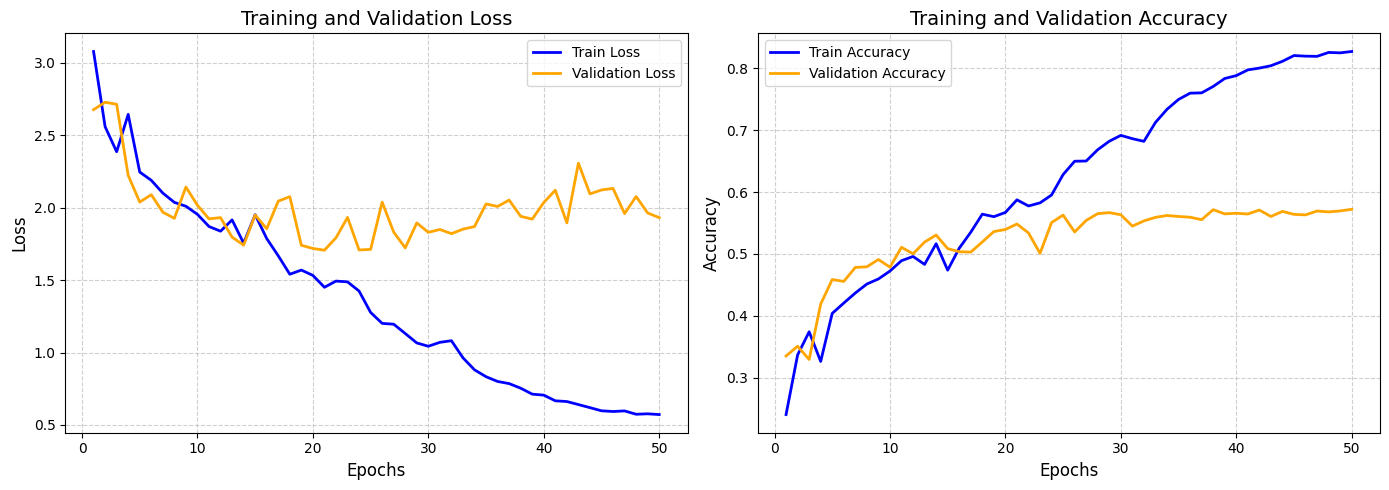

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ==========================================
# 1. VẼ BIỂU ĐỒ LOSS VÀ ACCURACY TỪ FILE JSON
# ==========================================
with open('resnet18_finetune_metrics.json', 'r') as f:
    history = json.load(f)

epochs = range(1, len(history['train_loss']) + 1)

plt.figure(figsize=(14, 5))

# Biểu đồ Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, history['train_loss'], label='Train Loss', color='blue', linewidth=2)
plt.plot(epochs, history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
plt.title('Training and Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Biểu đồ Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, history['train_acc'], label='Train Accuracy', color='blue', linewidth=2)
plt.plot(epochs, history['val_acc'], label='Validation Accuracy', color='orange', linewidth=2)
plt.title('Training and Validation Accuracy', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('training_curves_finetune.png', dpi=300)
plt.show()
